# Notebook 22 — Ontario renewable-resource pilot: Bronze → Atlite Silver → SQL candidate

This formal pilot carries Notebook 20's weather conversion and Notebook 21's technology
crosswalk through **Ontario polygons of the existing prov_quant 25 km basemap**. It uses
new ERA5 weather, rather than sparse preselected CANOE cell profiles, and keeps parent
region IDs for later schema integration. CANOE supplies the two generator identities and
cost selectors; weather-derived CFs come from Atlite.

Run cell by cell using the repository `.venv`. **The default run plans requests and tests
the cached one-day weather; it does not launch the full-year download.** Section 5 is the
only CDS network action. A complete annual SQL candidate is generated only after all
months, all Ontario regions and the model-unit checks pass. No production database is
modified. The acquisition and conversion helpers are pilot code, not yet registered in
the production Bronze/Silver orchestrators.

Flow: source snapshots + raw monthly ERA5 payloads → prepared weather + hourly regional
CFs → complete-year means + maps → ATB costs → validated insert-only `renewables.sql`.

References: [ERA5 single levels](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels),
[Atlite shape/layout aggregation](https://atlite.readthedocs.io/en/master/ref_api.html),
[ATB 2024 data](https://atb.nlr.gov/electricity/2024/data),
[ATB wind](https://atb.nlr.gov/electricity/2024b/land-based_wind),
[CANOE electricity](https://github.com/CANOE-main/canoe-electricity).


## 1. Load the explicit pilot configuration
Weather year, generator reference, cost year, model vintage and dollar year are separate choices.


In [1]:
from pathlib import Path
from importlib.metadata import version
import json
import sys
import tomllib
import sqlite3
import calendar

import atlite
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/geocanoe').is_dir())
sys.path.insert(0, str(ROOT / 'notebooks/support'))
import renewables_pilot as pilot

CONFIG_PATH = ROOT / 'config/renewables_pilots/ontario_25km.toml'
CONFIG = tomllib.loads(CONFIG_PATH.read_text(encoding='utf-8'))
SISTER = ROOT.parent / 'canoe-electricity-main'
SCHEMA_PATH = ROOT.parent / 'temoa/temoa/db_schema/temoa_schema_v4.sql'
assert SCHEMA_PATH.is_file(), 'Select the target Temoa v4 schema source before SQL validation.'
assert CONFIG['integration']['capacity_unit'] == 'MW'
assert CONFIG['integration']['electricity_unit'] == 'MWh'
assert CONFIG['integration']['annual_model_hours'] == 8760
VERSIONS = {name: version(name) for name in ['atlite', 'cdsapi', 'xarray', 'geopandas', 'numpy', 'pandas']}
assert VERSIONS['atlite'] == '0.7.0', 'Review the weather adapter before upgrading Atlite.'
print('Kernel:', sys.executable)
display(pd.Series(VERSIONS, name='version'))
display(pd.Series(CONFIG, dtype=object))


Kernel: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\.venv\Scripts\python.exe


atlite          0.7.0
cdsapi          0.7.7
xarray       2026.9.0
geopandas       1.1.3
numpy           2.3.1
pandas          2.3.1
Name: version, dtype: object

label                                                            ontario_25km
basemap                     data_files/processed/basemaps/prov_quant_basem...
province_boundaries                 data_files/raw/basemaps/lpr_000b21a_e.shp
weather_year                                                             2018
months                                [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
grid_degrees                                                             0.25
max_new_requests_per_run                                                    3
technology                  {'wind_plant_loss': 0.134, 'pv_ilr': 1.34, 'in...
integration                 {'model_period': 2025, 'vintage': 2025, 'cost_...
dtype: object

## 2. Select Ontario by its actual boundary, retaining parent region IDs
The basemap's `province_codes` is study-area metadata shared by every row, so it cannot
select Ontario. Use the Statistics Canada `PRUID=35` polygon instead. Select cells whose
centroids lie in Ontario, then clip their production footprints to Ontario. The clipped
footprint, not a whole cross-border cell, determines weather weights. This is a pilot
region-selection rule; narrow boundary slivers with non-Ontario centroids are excluded.

This is a resource CF assessment, with uniform capacity density over each production
polygon. No eligibility exclusions, deployment density, capacity ceilings or shared-land
constraints are inferred. Those are a separate siting/potential layer. Water and protected
land are not silently treated as developable capacity.


,region,production_area_km2,on_fraction
region,,,
R0,R0,624.921612,0.999875
R1,R1,623.413562,0.997462
R2,R2,619.914225,0.991863
R3,R3,363.805398,0.582089
R4,R4,318.578647,0.509726


Ontario production regions: 1564
Pilot output: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\processed\renewables\ontario_pilot\bbc9e0f04c45a0de


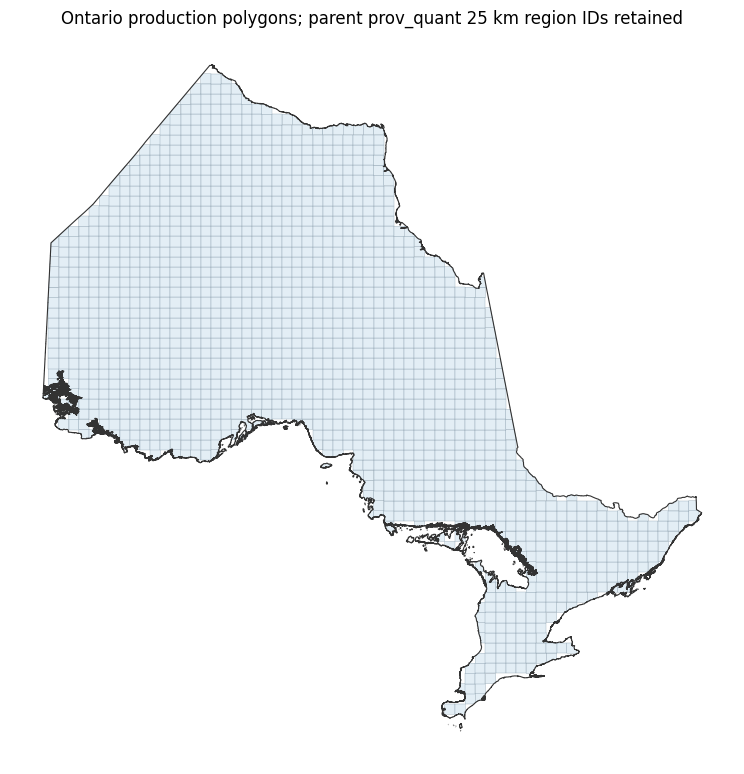

In [2]:
BASEMAP = ROOT / CONFIG['basemap']
BOUNDARIES = ROOT / CONFIG['province_boundaries']
regions, ontario_boundary = pilot.select_ontario(BASEMAP, BOUNDARIES)
bundle, generator_rows = pilot.snapshot_sources(ROOT, SISTER, CONFIG)
PILOT_ID = pilot.identity({'config': CONFIG, 'basemap_sha256': pilot.sha256(BASEMAP),
                           'boundary_sha256': pilot.sha256(BOUNDARIES), 'source_bundle': bundle.name,
                           'helper_sha256': pilot.sha256(pilot.__file__)})
OUT = ROOT / 'data_files/processed/renewables/ontario_pilot' / PILOT_ID
OUT.mkdir(parents=True, exist_ok=True)
BRONZE = ROOT / 'data_files/raw/era5/ontario_pilot'
SILVER = OUT / 'monthly_profiles'
regions.to_file(OUT / 'ontario_production_regions.gpkg', layer='regions', driver='GPKG', index=False)
display(regions[['region', 'production_area_km2', 'on_fraction']].head())
print('Ontario production regions:', len(regions))
print('Pilot output:', OUT)
fig, ax = plt.subplots(figsize=(8, 8))
ontario_boundary.boundary.plot(ax=ax, color='#333333', linewidth=0.8)
regions.plot(ax=ax, color='#e3eef5', edgecolor='#718899', linewidth=0.2)
ax.set_title('Ontario production polygons; parent prov_quant 25 km region IDs retained')
ax.set_axis_off()
fig.tight_layout()
fig.savefig(OUT / 'ontario_basemap_preview.png', dpi=150)
plt.show()


## 3. Bronze source contract: immutable weather and engineering/economic references
The source bundle copies named non-secret files: the full generator registry, params,
currency tables, pinned ATBe CSV and class-tagged T1 curve/specification. Raw copies are
hashed and reused. Display only the solar/wind rows; do not import CANOE execution modules.

ERA5 Bronze stores original CDS payload bytes plus request JSON, checksum and size. It is
independent of turbine choice and the scenario cost year. Raw radiation/weather preparation
belongs to Silver, even though earlier exploratory cutouts were stored under `raw/`.


In [3]:
display(generator_rows[['base_tech', 'atb_display_name', 'atb_scenario', 'atb_min_year', 'out_comm']])
print('Reference bundle:', bundle)
print('Gold adapter commodity mapping: CANOE elc_tx -> GeoCANOE elc; ethos retained.')
print('Wind physical configuration: T1 6 MW / 170 m rotor / 115 m hub, matching the onshore cost row.')
print('PV configuration: CSi horizontal tracking; ILR and losses explicitly defined in CONFIG.')


,base_tech,atb_display_name,atb_scenario,atb_min_year,out_comm
code,,,,,
solar,E_SOL_PV,Utility PV - Class 3,Moderate,2022,elc_tx
wind_onshore,E_WND_ON,Land-Based Wind - Class 7 - Technology 1,Moderate,2022,elc_tx


Reference bundle: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\raw\renewables\source_bundles\e4a7bbaa0a64436c
Gold adapter commodity mapping: CANOE elc_tx -> GeoCANOE elc; ethos retained.
Wind physical configuration: T1 6 MW / 170 m rotor / 115 m hub, matching the onshore cost row.
PV configuration: CSi horizontal tracking; ILR and losses explicitly defined in CONFIG.


## 4. Review the complete Ontario request plan before acquisition
One buffered bounding box covers the selected production polygons on the standard 0.25°
grid. Requests are split by calendar month and feature group (wind, influx, temperature):
**36 requests for a full year**, executed sequentially. The estimate below is uncompressed
float32 variable storage, not a promised download size; server NetCDF/ZIP format,
coordinates, temporary storage and float64 Silver conversion add overhead.

Each request has a content identity. Reruns verify the payload checksum and skip it.
The per-run request budget defaults to three new requests (one month). HTTP operations use at most three client attempts with 30-second retry delays and a
60-second HTTP timeout. Persistent failures stop the cell; resume after the server issue
clears. Normal CDS job queueing/polling may take longer than an HTTP operation.
If CDS request limits require smaller batches, revise the plan explicitly before downloading.


In [4]:
PLAN = pilot.request_plan(regions, CONFIG['weather_year'], CONFIG['months'], CONFIG['grid_degrees'])
plan_table = pd.DataFrame([{key: value for key,value in item.items() if key != 'request'} for item in PLAN])
display(plan_table)
print('CDS requests:', len(PLAN))
print('Buffered bounding box [N,W,S,E]:', PLAN[0]['request']['area'])
print('Estimated raw float32 variable volume (GB):', plan_table.float32_bytes_estimate.sum()/1e9)
print('Plan months:', CONFIG['months'])
assert len(PLAN) == len(set(item['request_id'] for item in PLAN))
pilot.manifest(OUT / 'request_plan.json', {'dataset':'reanalysis-era5-single-levels', 'plan':PLAN,
                                         'max_new_requests_per_run':CONFIG.get('max_new_requests_per_run')})


,month,feature,request_id,hours,weather_cells_estimate,float32_bytes_estimate
0,1,wind,0d5fcf52f722c9f3,744,5394,80262720
1,1,influx,24b0cc3af2e8c365,744,5394,64210176
2,1,temperature,910ab8aa79fe5f96,744,5394,48157632
3,2,wind,673fd2422a78fff4,672,5394,72495360
4,2,influx,a72b3bfcd0366796,672,5394,57996288
5,2,temperature,9e3df2cba93b68b9,672,5394,43497216
6,3,wind,4cfa152b8366d8b7,744,5394,80262720
7,3,influx,6e3487040223993f,744,5394,64210176
8,3,temperature,a58bb412b905286e,744,5394,48157632
9,4,wind,4887a0cc9528eb63,720,5394,77673600


CDS requests: 36
Buffered bounding box [N,W,S,E]: [57.0, -95.5, 41.75, -74.0]
Estimated raw float32 variable volume (GB): 2.26806912
Plan months: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


## 5. Acquire ERA5 Bronze — explicit network switch
Review section 4, then set `RUN_ACQUISITION=True` to acquire all missing requests sequentially. An optional
max_new_requests_per_run setting can cap a test run. Rerun to resume after failure. CDS credentials remain in the home `.cdsapirc`; never
write them into manifests. Dataset terms must already be accepted. Nothing in later cells
triggers CDS acquisition automatically.


In [5]:
RUN_ACQUISITION = True
# Verify every cached request before deciding whether CDS is needed.
import importlib
pilot = importlib.reload(pilot)
pending_requests = []
status_rows = []
for item in PLAN:
    payload = BRONZE / f"{item['request_id']}.payload"
    record = BRONZE / f"{item['request_id']}.json"
    verified = False
    if payload.is_file():
        if not record.is_file():
            raise ValueError(f'Cached payload has no manifest: {payload}')
        cached = json.loads(record.read_text(encoding='utf-8'))
        if (payload.stat().st_size == 0
                or cached.get('request') != item['request']
                or cached.get('sha256') != pilot.sha256(payload)):
            raise ValueError(f'Invalid Bronze cache; inspect before retrying: {payload}')
        verified = True
    else:
        pending_requests.append(item)
    status_rows.append({'month': item['month'], 'feature': item['feature'],
                        'payload_present': payload.is_file(),
                        'manifest_present': record.is_file(),
                        'cache_verified': verified})

print(f'Verified cached requests: {len(PLAN) - len(pending_requests)}/{len(PLAN)}')
if not pending_requests:
    print('All Bronze requests are cached and verified. CDS API skipped.')
elif RUN_ACQUISITION:
    print('Missing requests:', len(pending_requests))
    print('New requests downloaded:', pilot.acquire(
        pending_requests, BRONZE, CONFIG.get('max_new_requests_per_run')))
else:
    print(f'{len(pending_requests)} requests missing. Set RUN_ACQUISITION=True to download.')

download_status = pd.DataFrame(status_rows)
# Refresh presence after acquisition; newly downloaded files are verified by acquire().
for index, item in enumerate(PLAN):
    payload = BRONZE / f"{item['request_id']}.payload"
    record = BRONZE / f"{item['request_id']}.json"
    download_status.loc[index, 'payload_present'] = payload.is_file()
    download_status.loc[index, 'manifest_present'] = record.is_file()
    if RUN_ACQUISITION and payload.is_file() and record.is_file():
        download_status.loc[index, 'cache_verified'] = True
display(download_status)


Verified cached requests: 3/36
Missing requests: 33


2026-10-20 15:26:30,156 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-20 15:26:30,693 INFO Request ID is 7aa8cc04-7296-4ae7-887b-d0dcfa8337be
2026-10-20 15:26:30,831 INFO status has been updated to accepted
2026-10-20 15:26:44,681 INFO status has been updated to running
2026-10-20 15:30:19,465 INFO status has been updated to successful


3a2de74e4ca799ea0c736585d1d3a83.nc:   0%|          | 0.00/34.3M [00:00<?, ?B/s]

2026-10-20 15:30:28,180 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-20 15:30:28,753 INFO Request ID is e0bfe462-c9b9-45f8-9018-960ca07c00e7
2026-10-20 15:30:28,881 INFO status has been updated to accepted
2026-10-20 15:30:50,606 INFO status has been updated to running
2026-10-20 15:34:45,934 INFO status has been updated to successful


a5f8baf2d855bf1981cc5c051113821b.nc:   0%|          | 0.00/10.1M [00:00<?, ?B/s]

2026-10-20 15:34:50,367 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-20 15:34:50,879 INFO Request ID is 10590b7f-27f2-4e21-9742-27af631c94bd
2026-10-20 15:34:51,008 INFO status has been updated to accepted
2026-10-20 15:35:12,930 INFO status has been updated to running
2026-10-20 15:37:38,843 INFO status has been updated to successful


be7545beaa8b7dca830827369c18162b.nc:   0%|          | 0.00/14.9M [00:00<?, ?B/s]

New requests downloaded: 3


,month,feature,payload_present,manifest_present,cache_verified
0,1,wind,True,True,True
1,1,influx,True,True,True
2,1,temperature,True,True,True
3,2,wind,True,True,True
4,2,influx,True,True,True
5,2,temperature,True,True,True
6,3,wind,False,False,False
7,3,influx,False,False,False
8,3,temperature,False,False,False
9,4,wind,False,False,False


## 6. Atlite Silver: raw preparation and native polygon aggregation
Process only months with all three Bronze feature groups. The weather adapter pins the
inspected **Atlite 0.7.0** preparation functions (including the solar radiation interval
handling). It supports raw NetCDF and ZIP-wrapped NetCDF responses; original bytes remain
in Bronze. No weather is downloaded here.

Use Atlite's `compute_indicatormatrix` with both geometries in EPSG:3347, then an area-based
layout for uniform capacity density. This preserves physical-area weighting rather than
averaging latitude/longitude grid cells equally. Assert complete weather coverage for
every selected region. Zero-capacity normalization must never masquerade as zero CF.

Convert the T1 wind curve at 115 m, then apply the declared plant loss once. Its assumed
25 m/s shutdown is inherited from Notebook 21 and still needs high-wind validation.
Convert PV at weather-cell level, apply ILR/inverter/additional loss and AC clipping
**before** spatial averaging. No bifacial gain, ATB CF uplift or ageing correction is added.
Silver outputs retain regional hourly CFs, UTC, hashes, geometry identity and configuration.


In [6]:
# Reload the local adapter after edits without restarting the kernel.
import importlib
importlib.invalidate_caches()
pilot = importlib.reload(pilot)
print('Adapter:', pilot.__file__)

monthly_paths = []
for month in CONFIG['months']:
    items = [item for item in PLAN if item['month'] == month]
    available = all((BRONZE / f"{item['request_id']}.payload").is_file()
                    and (BRONZE / f"{item['request_id']}.json").is_file() for item in items)
    if available:
        path = pilot.transform_month(items, BRONZE, SILVER, regions, bundle, CONFIG['technology'])
        monthly_paths.append(path)
        print('Verified Silver month:', month, path.name)
    else:
        print('Awaiting complete Bronze month:', month)


Adapter: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\notebooks\support\renewables_pilot.py
Verified Silver month: 1 month_01_8a10fd5a51130b4b.nc
Verified Silver month: 2 month_02_6db544e209948609.nc
Awaiting complete Bronze month: 3
Awaiting complete Bronze month: 4
Awaiting complete Bronze month: 5
Awaiting complete Bronze month: 6
Awaiting complete Bronze month: 7
Awaiting complete Bronze month: 8
Awaiting complete Bronze month: 9
Awaiting complete Bronze month: 10
Awaiting complete Bronze month: 11
Awaiting complete Bronze month: 12


## 7. Offline implementation check using Notebook 20's cached one-day weather
This optional smoke check exercises the same native matrix, full regional coverage checks,
T1/PV conversions and plots without requiring a new annual download. Only Ontario regions
fully inside the small existing cutout are used. These means are **daily**, not annual.
They never feed the annual SQL candidate.


In [7]:
smoke_paths = sorted((ROOT / 'data_files/raw/era5/atlite_pilot').glob('*.nc'))
smoke_profiles = None
if len(smoke_paths) == 1:
    smoke_cutout = atlite.Cutout(smoke_paths[0])
    _, _, coverage = pilot.aggregation_matrix(smoke_cutout, regions)
    smoke_regions = regions.loc[coverage >= 0.999].copy()
    if not smoke_regions.empty:
        smoke_profiles, smoke_coverage = pilot.convert(smoke_cutout, smoke_regions, bundle, CONFIG['technology'])
        smoke_profiles.to_netcdf(OUT / 'smoke_daily_regional_profiles.nc')
        display(smoke_profiles.mean('time').to_dataframe().head())
        print('Smoke-check fully covered Ontario regions:', len(smoke_regions))
else:
    print('Set an explicit smoke cutout path if a one-day diagnostic is wanted.')


DLL load failed while importing _eccodes: The specified module could not be found.
c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\.venv\Lib\site-packages\xarray\backends\plugins.py:109: RuntimeWarning: Engine 'cfgrib' loading failed:
DLL load failed while importing _eccodes: The specified module could not be found.
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


,wind_cf,solar_cf
region,,
R17,0.305177,0.481638
R18,0.290257,0.489963
R19,0.331705,0.494422
R20,0.385834,0.492448
R21,0.379132,0.484223


Smoke-check fully covered Ontario regions: 83


## 8. Full-year coverage gate and annual resource Silver
Require all 12 calendar months, the expected 8,760/8,784 timestamps, finite data and every
Ontario region. Annual CF is a mean over time; no clustering is involved. The resource
assessment is uniform-area-weighted, not a site selection or eligible-capacity supply curve.


In [8]:
annual_cf = None
hourly_on = None
if sorted(CONFIG['months']) == list(range(1,13)) and len(monthly_paths) == 12:
    hourly_on, annual_cf = pilot.annual_profiles(monthly_paths, CONFIG['weather_year'])
    assert set(annual_cf.index.astype(str)) == set(regions.region.astype(str))
    annual_cf = annual_cf.reindex(regions.region)
    annual_cf.to_csv(OUT / 'ontario_annual_cf.csv')
    hourly_on.to_netcdf(OUT / 'ontario_hourly_cf.nc')
    display(annual_cf.describe())
else:
    print(f'Annual export pending: {len(monthly_paths)}/12 prepared monthly products. Daily smoke data are excluded.')


Annual export pending: 2/12 prepared monthly products. Daily smoke data are excluded.


## 9. Map complete model polygons and report weather coverage separately
Annual maps appear when the full year is ready. Otherwise the smoke region uses explicit
daily labels. Wind and solar share the same extent. The production polygon is coloured
as a region; this avoids the sliver plot from Notebook 21's sparse imported candidates.
No interpolation is used to fill missing annual values or geography.


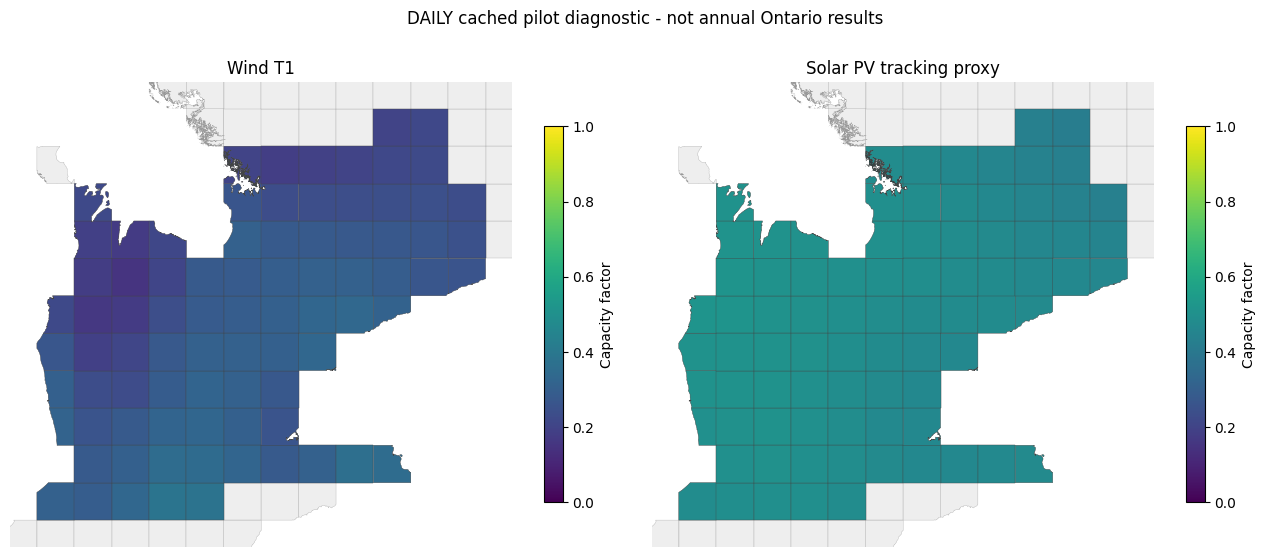

In [9]:
if annual_cf is not None:
    map_regions = regions
    map_values = annual_cf
    map_label = f"Annual {CONFIG['weather_year']} ERA5-derived regional CF"
elif smoke_profiles is not None:
    map_regions = smoke_regions
    map_values = smoke_profiles.mean('time').to_dataframe()[['wind_cf','solar_cf']]
    map_label = 'DAILY cached pilot diagnostic - not annual Ontario results'
else:
    map_regions = None

if map_regions is not None:
    mapped = map_regions.join(map_values)
    xmin,ymin,xmax,ymax = mapped.total_bounds
    pad = 0.06*max(xmax-xmin,ymax-ymin)
    context = regions.cx[xmin-pad:xmax+pad, ymin-pad:ymax+pad]
    fig,axes = plt.subplots(1,2,figsize=(13,6))
    for ax,name,title in zip(axes,['wind_cf','solar_cf'],['Wind T1','Solar PV tracking proxy']):
        context.plot(ax=ax,color='#eeeeee',edgecolor='#999999',linewidth=0.2)
        mapped.plot(ax=ax,column=name,cmap='viridis',vmin=0,vmax=1,edgecolor='#444444',linewidth=0.25,
                    legend=True,legend_kwds={'label':'Capacity factor','shrink':0.7})
        ax.set(title=title,xlim=(xmin-pad,xmax+pad),ylim=(ymin-pad,ymax+pad))
        ax.set_axis_off()
    fig.suptitle(map_label)
    fig.tight_layout()
    fig.savefig(OUT / ('annual_cf_preview.png' if annual_cf is not None else 'daily_smoke_preview.png'),dpi=150)
    plt.show()


## 10. ATB costs and GeoCANOE integration units
Use the two imported CANOE rows and their ATB 2024 v3 selectors, Moderate/Market, CRP=20.
Read the selected cost year explicitly. Correct the **source dollar year to 2022 USD**
rather than inheriting the sibling config's 2021 label. Use the snapshotted CANOE exchange
and GDP-deflator tables to convert to the chosen CAD dollar year. No generic web FX rate
is substituted. These conversion tables themselves are an explicit inherited assumption.

The pilot SQL uses **MW capacity, MWh/year electricity**, and **million CAD2020/MW** costs
by default. `USD/kW × 1000 kW/MW × CAD conversion / 1e6` gives investment cost on this
basis; fixed O&M has an additional per-year denominator. This differs from CANOE's
GW/PJ convention. `capacity_to_activity=8760 MWh/(MW year)` matches the current annual
GeoCANOE representation, independent of the weather-year timestamp count.

Before an actual merge, reconcile all target cost scales; GeoCANOE contains legacy unit
labels and cannot be assumed globally consistent. OCC excludes grid connection; no spur
cost is added here because the future electrical-network accounting must decide that boundary.


In [10]:
costs = pilot.selected_costs(bundle, CONFIG['integration']['cost_year'],
                              CONFIG['integration']['currency_year'], CONFIG['integration']['currency_scale'])
display(costs)
print('Target electricity commodity: elc (MWh basis); renewable source input: ethos.')
print('Investment/fixed costs are positive; CFs remain independently ERA5-derived, without ATB CF indexing.')


,tech,atb_display_name,cost_year,invest,fixed,source_currency_year,cad_factor,units
code,,,,,,,,
wind_onshore,E_WND_ON,Land-Based Wind - Class 7 - Technology 1,2030,1.360857,0.030882,2022,1.055309,million CAD2020/MW
solar,E_SOL_PV,Utility PV - Class 3,2030,1.101428,0.018986,2022,1.055309,million CAD2020/MW


Target electricity commodity: elc (MWh basis); renewable source input: ethos.
Investment/fixed costs are positive; CFs remain independently ERA5-derived, without ATB CF indexing.


## 11. Build and validate renewables.sql without merging a production model
Annual technologies use `limit_annual_capacity_factor` with `operator='le'`, not hourly
`capacity_factor_process` rows. Add technology, efficiency, MW→MWh capacity conversion,
30-year life and selected investment/fixed costs. Preserve parent region IDs. Do not copy
CANOE's `elc_tx` into GeoCANOE, replace incumbent `ELC_GEN`, set zero CF for missing regions,
or create unvalidated resource/build-capacity limits.

The candidate is insert-only: it checks v4 metadata, target periods, annual time structure,
existing ethos/elc commodities and region IDs, and absence of conflicting renewable techs.
Failure of a prerequisite rolls back. A disposable database instantiated from the selected
schema validates the candidate, foreign keys and expected row counts. This is a database
contract check, not a solver or economic validation. The target's incumbent supply and
cost-unit policy remain future integration decisions.

Until the annual coverage gate passes, `renewables.sql` is a **blocked placeholder** that
raises a rollback error if executed. It cannot silently import daily or partial-year CFs.


In [11]:
SQL_PATH = OUT / 'renewables.sql'
sql_validation = None
if annual_cf is not None:
    sql_validation = pilot.sql_candidate(annual_cf, costs, SCHEMA_PATH, SQL_PATH,
        vintage=CONFIG['integration']['vintage'], period=CONFIG['integration']['model_period'])
    display(pd.Series(sql_validation))
else:
    SQL_PATH.write_text(
        "-- BLOCKED: awaiting complete Ontario annual ERA5/Atlite CFs. Not a merge candidate.\n"
        "BEGIN;\nCREATE TEMP TABLE _renewables_pending (ok INTEGER);\n"
        "CREATE TEMP TRIGGER _renewables_pending_guard BEFORE INSERT ON _renewables_pending "
        "BEGIN SELECT RAISE(ROLLBACK, 'Complete Ontario annual CFs required; rerun Notebook 22'); END;\n"
        "INSERT INTO _renewables_pending VALUES(0);\n", encoding='utf-8')
    print('Wrote blocked SQL placeholder; no annual values fabricated:', SQL_PATH)

contract = {
    'tables': ['technology','efficiency','capacity_to_activity','lifetime_tech','cost_invest','cost_fixed','limit_annual_capacity_factor'],
    'technology_ids': ['E_WND_ON','E_SOL_PV'], 'commodity_map': {'ethos':'ethos','elc_tx':'elc'},
    'capacity_unit':'MW','electricity_unit':'MWh','model_year_hours':8760,
    'sql_ready':sql_validation is not None, 'production_ready':False,
    'no_production_merge_performed':True,
}
pilot.manifest(OUT / 'renewables_schema_contract.json', contract)


Wrote blocked SQL placeholder; no annual values fabricated: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\processed\renewables\ontario_pilot\bbc9e0f04c45a0de\renewables.sql


## 12. Pilot manifest and promotion criteria
The pilot is reproducible but remains **not production-ready**. Promotion requires a
complete annual run, Canadian performance validation, accepted PV loss/bifacial/ageing
policy, confirmed wind high-speed behaviour, compatible currency/activity/capacity units,
and a decision on incumbent electricity supply and land/build limits.

Proposed production stages after this notebook is reviewed:
1. Bronze `era5_renewables`: stable raw weather requests/payloads/manifests.
2. Bronze `renewable_technology_references`: ATB release, class-tagged curves and CANOE row snapshots.
3. Silver `renewables_atlite`: basemap-keyed regional hourly/annual profiles with transformation hashes.
4. Schema adapter `renewables`: scenario-selected costs, annual CF constraints and insert-only SQL.

Keep acquisition independent of turbine and model vintage; keep costs separate from Silver
weather conversion. Register these in the production orchestrators/source registry only
after the pilot's data and model contracts are accepted. National expansion reuses this
contract with explicit request sizing and bounded acquisition, rather than repeated scraping.


In [12]:
pilot.manifest(OUT / 'pilot_manifest.json', {
    'pilot_id':PILOT_ID, 'config':CONFIG, 'versions':VERSIONS,
    'config_sha256':pilot.sha256(CONFIG_PATH), 'helper_sha256':pilot.sha256(pilot.__file__),
    'basemap_sha256':pilot.sha256(BASEMAP),'province_boundaries_sha256':pilot.sha256(BOUNDARIES),
    'source_bundle':str(bundle),'source_bundle_sha256':pilot.sha256(bundle/'manifest.json'),
    'regions':len(regions),'request_count':len(PLAN),'completed_silver_months':len(monthly_paths),
    'annual_cf_ready':annual_cf is not None,'sql_validation':sql_validation,
    'schema_sha256':pilot.sha256(SCHEMA_PATH), 'production_ready':False,
    'sql_status':'validated annual candidate' if sql_validation else 'blocked pending complete annual weather',
    'limitations':['Uniform-area resource weighting; no eligibility/potential layer',
                  'PV bifacial/backtracking/loss/ageing calibration pending',
                  'Wind shutdown/air-density/net-plant calibration pending',
                  'Target cost scale and incumbent electricity-supply policy need reconciliation'],
})
print('Pilot products:', OUT)
print('Production database modified: False')


Pilot products: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\processed\renewables\ontario_pilot\bbc9e0f04c45a0de
Production database modified: False
